# MangoLeaf AI: seven-class training experiment v4

**Experimental candidate: `model-v4.0.0`. This does not update the application.**

This notebook includes data preparation, training, calibration, Grad-CAM, and export.
Healthy leaves and healthy fruits remain separate. The other v3 training settings stay the same.
Run cells from top to bottom in a Colab GPU runtime. Train one model, not the two-model background experiment.

Final test predictions and rejection thresholds belong in the separate v4 threshold notebook.
The original evaluation images were used in earlier development; results on them are reused-data evidence.


## Before running: upload folders to Google Drive

- `mango_dataset_v3/`: the original seven source folders, including `healthy_leaf/` and `healthy_fruit/`.
- The original `dataset_split/` folder containing `train/`, `val/`, and `test/` with the merged `healthy/` class.
  It supplies historical image membership. Point to the inner folder if Drive has two `dataset_split` levels.
- No masks, replacement backgrounds, or OOD photos are needed for training. OOD photos are used in the second notebook.

Generated outputs go to `MyDrive/mangoleaf_experiments/v4/training/v4-training-<timestamp>-<id>/`.
The timestamp and short ID keep repeated runs separate. Input folders can stay in their existing locations.

Extract input ZIPs first. This notebook reads input folders without changing their images.
The 62 manually reviewed image identities are embedded below, including the 13 intentional filename changes.
Keep both healthy classes even though healthy fruit has fewer examples.


## 1. Set paths and load the runtime

**Purpose:** select inputs and retain the v3 training settings.
**Action:** change the three Drive paths if needed. Select Runtime > Change runtime type > GPU.
**Expected result:** runtime versions, seven class names, and the training output folder are printed. This cell does not start training.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import csv, hashlib, json, math, os, random, shutil, subprocess, sys, uuid, zipfile
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath
import numpy as np
import tensorflow as tf
from PIL import Image

SEED = 42
CLASS_NAMES = ['anthracnose', 'bacterial_black_spot', 'bacterial_canker',
               'healthy_fruit', 'healthy_leaf', 'mango_scab', 'sooty_mold']
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
CONFIDENCE_THRESHOLD = 0.70
MIN_ID_RETENTION = 0.95  # Accepted mango images; not necessarily correct diagnoses.
MODEL_VERSION = 'model-v4.0.0'
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
PREPROCESSING = 'TensorFlow RGB decode; bilinear 224x224, no antialias; float32 0-255; model rescales internally'
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy('float32')
RUNTIME = {'python': sys.version, 'tensorflow': tf.__version__, 'keras': tf.keras.__version__,
           'numpy': np.__version__, 'pillow': Image.__version__}
print('Runtime:', RUNTIME)

RAW_DIR = Path('/content/drive/MyDrive/mango_dataset_v3')
BASELINE_SPLIT_DIR = Path('/content/drive/MyDrive/mangoleaf_v3/dataset_split/dataset_split')
# Keep every generated v4 run under the same experiment folder.
EXPERIMENT_ROOT = Path('/content/drive/MyDrive/mangoleaf_experiments/v4')
OUTPUT_ROOT = EXPERIMENT_ROOT / 'training'
PHASH_DISTANCE = 5
STAGE1_EPOCHS, STAGE1_LR = 5, 1e-3
STAGE2_EPOCHS, STAGE2_LR = 10, 1e-5
AUG_ROTATION_DEG, AUG_ZOOM, AUG_BRIGHTNESS, AUG_SHEAR = 30, 0.20, 0.20, 0.20
AUG_FLIP = 'horizontal_and_vertical'
QUANTIZE_FLOAT16 = False
EVALUATION_STATUS = 'previously_used'
EVALUATION_NOTES = 'The original v3 test/OOD report images influenced earlier development.'

# Install hashing support without changing Colab's TensorFlow or NumPy versions.
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', '--no-deps', 'ImageHash==4.3.2'], check=True)
import imagehash
from PIL import ImageOps
print('Class order:', CLASS_NAMES)
print('Training output root:', OUTPUT_ROOT)


Mounted at /content/drive
Runtime: {'python': '3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]', 'tensorflow': '2.20.0', 'keras': '3.13.2', 'numpy': '2.1.3', 'pillow': '11.3.0'}
Class order: ['anthracnose', 'bacterial_black_spot', 'bacterial_canker', 'healthy_fruit', 'healthy_leaf', 'mango_scab', 'sooty_mold']
Training output root: /content/drive/MyDrive/mangoleaf_experiments/v4/training


In [2]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def object_hash(value):
    text = json.dumps(value, sort_keys=True, separators=(',', ':'), ensure_ascii=True)
    return hashlib.sha256(text.encode()).hexdigest()


def write_json_once(path, value):
    with Path(path).open('x', encoding='utf-8') as handle:
        json.dump(value, handle, indent=2, allow_nan=False)
        handle.write('\n')


def list_images(folder):
    folder = Path(folder)
    if not folder.is_dir():
        raise FileNotFoundError(f'Image folder missing: {folder}')
    paths = sorted(p for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    if not paths:
        raise ValueError(f'No supported images in {folder}')
    return paths


def verify_records_unchanged(rows):
    for row in rows:
        if sha256_file(row['path']) != row['sha256']:
            raise RuntimeError('Image changed: ' + row['path'])


def inside(root, relative):
    relative = PurePosixPath(relative)
    if relative.is_absolute() or '..' in relative.parts or '\\' in str(relative):
        raise ValueError('Unsafe relative path: ' + str(relative))
    target = (Path(root) / str(relative)).resolve()
    if not target.is_relative_to(Path(root).resolve()) or target == Path(root).resolve():
        raise ValueError('Path must stay inside its output folder.')
    return target


def extract_dataset(archive, rows, destination):
    # Extract only recorded images, then verify their contents before inference.
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=False)
    expected = {r['relativePath']: r for r in rows}
    if len(expected) != len(rows):
        raise ValueError('The image manifest repeats a destination path.')
    with zipfile.ZipFile(archive) as bundle:
        names = bundle.namelist()
        if len(names) != len(set(names)) or set(names) != set(expected):
            raise ValueError('Dataset ZIP entries differ from the image manifest.')
        for name, row in expected.items():
            target = inside(destination, name)
            if bundle.getinfo(name).file_size != row['bytes']:
                raise ValueError('Image size changed in dataset ZIP: ' + name)
            target.parent.mkdir(parents=True, exist_ok=True)
            with bundle.open(name) as source, target.open('xb') as output:
                shutil.copyfileobj(source, output)
            if sha256_file(target) != row['sha256']:
                raise ValueError('Image contents changed in dataset ZIP: ' + name)
    return [{**r, 'path': str(inside(destination, r['relativePath']))} for r in rows]


def verify_artifacts(folder, artifacts):
    for relative, expected in artifacts.items():
        path = inside(folder, relative)
        if not path.is_file() or sha256_file(path) != expected:
            raise RuntimeError('Missing or changed saved artifact: ' + relative)


def load_pixels(path):
    # This matches v3's Keras image loader. Do not divide by 255 again.
    pixels = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    pixels.set_shape((None, None, 3))
    return tf.image.resize(pixels, IMAGE_SIZE, method='bilinear',
                           preserve_aspect_ratio=False, antialias=False)


def predict_records(model, rows):
    output = []
    for start in range(0, len(rows), BATCH_SIZE):
        batch = rows[start:start + BATCH_SIZE]
        verify_records_unchanged(batch)
        pixels = tf.stack([load_pixels(r['path']) for r in batch])
        values = model(pixels, training=False).numpy()
        if values.shape != (len(batch), len(CLASS_NAMES)) or not np.isfinite(values).all():
            raise ValueError('The model must return seven finite probabilities per image.')
        output.extend(values.tolist())
    if not output:
        raise ValueError('Cannot predict an empty image collection.')
    return np.asarray(output, dtype=np.float32)


def weight_digest(model):
    digest = hashlib.sha256()
    for variable in model.weights:
        values = variable.numpy()
        digest.update(str(values.shape).encode())
        digest.update(str(values.dtype).encode())
        digest.update(values.tobytes())
    return digest.hexdigest()


def print_class_probabilities(probabilities, title):
    # Sort label-score pairs for display; keep the model's class order unchanged.
    ranked = sorted(zip(CLASS_NAMES, map(float, probabilities), strict=True),
                    key=lambda item: item[1], reverse=True)
    print('\n' + title)
    for label, probability in ranked:
        print(f"{label.replace('_', ' ').title():<24} {probability * 100:6.2f}%")


In [3]:
# These identities came from the user's reviewed non-duplicate list.
# Names may change; the SHA-256 hash identifies the exact file contents.
REVIEWED_IMAGES = [{'label': 'anthracnose', 'currentName': 'verified mango leaf disease 21.jpg', 'historicalName': 'verified mango leaf disease 21.jpg', 'sha256': 'a557157b1e887d6f8f7067efbaa97447074114b2967c3c2337656d1936b45102'}, {'label': 'anthracnose', 'currentName': 'verified mango leaf disease 20.jpg', 'historicalName': 'verified mango leaf disease 20.jpg', 'sha256': '87dad59aa6422d959e3fcfffd35ddca9c918e858dd7b220f1e016ae09d741f6f'}, {'label': 'anthracnose', 'currentName': 'DSC_0119.JPG', 'historicalName': 'DSC_0119.JPG', 'sha256': '01e6fd123c9ae054d2d904fef25f543279c6c74914d44a33cd9c7488ca2861c6'}, {'label': 'anthracnose', 'currentName': 'DSC_0488.JPG', 'historicalName': 'DSC_0488.JPG', 'sha256': 'ee9676472204c9cdd0830dce3be63a9d47e646ecb9d2c70126ddcdac063e4ecd'}, {'label': 'anthracnose', 'currentName': 'DSC_0970.JPG', 'historicalName': 'DSC_0970.JPG', 'sha256': '8b5d0b0e2500ff762a773b326c6a0a3ab545e51e682a253d3776be738d61123c'}, {'label': 'anthracnose', 'currentName': 'Anthracnose on young leaves.jpeg', 'historicalName': 'Anthracnose on young leaves.jpeg', 'sha256': '5c10b4851fd67db6b5a21677e725d124491633afea45186fbe2e2a6f9bd554ec'}, {'label': 'anthracnose', 'currentName': 'AnthracnoseonMangoLeaf.jpeg', 'historicalName': 'AnthracnoseonMangoLeaf.jpeg', 'sha256': '52a0fa64a504139aa65e6cbf807ecae21be6f4933bc4c1d5e2d8797a54de7227'}, {'label': 'sooty_mold', 'currentName': 'IMG_20260219_135000.jpg', 'historicalName': 'IMG_20260219_135000.jpg', 'sha256': '2a22ee7f89ea03ad9ee924b5815ae71576d6ccd3305576dccc6f3bf00e31fce3'}, {'label': 'sooty_mold', 'currentName': 'viber_image_2024-11-15_13-17-51-567.jpg', 'historicalName': 'viber_image_2024-11-15_13-17-51-567.jpg', 'sha256': 'd785e72ca8291a194d5f56f2c75d2087ca3fd9728549246b888a3b964ce5b3c9'}, {'label': 'sooty_mold', 'currentName': 'IMG_20260219_134935.jpg', 'historicalName': 'IMG_20260219_134935.jpg', 'sha256': '6c1c6c90f2dbfdb3ab1d451b90a9ce2769222aaa237bb820bf55f782e63498d5'}, {'label': 'sooty_mold', 'currentName': 'DSC_1029.JPG', 'historicalName': 'DSC_1029.JPG', 'sha256': '7dfd201d72ea78a4557fdc5c5bddb594af538ff0270e020e73c9f382b3fa6f74'}, {'label': 'sooty_mold', 'currentName': '724869371_27534362222843583_7670640125862653147_n.jpg', 'historicalName': '724869371_27534362222843583_7670640125862653147_n.jpg', 'sha256': '81c5a02299de1f2d66627a0f709a4f0c3235066749f7f8b203840b86f8a93b3c'}, {'label': 'sooty_mold', 'currentName': '45a36510-0844-4baa-9795-3de7e0236896.jpg', 'historicalName': '45a36510-0844-4baa-9795-3de7e0236896.jpg', 'sha256': '32d90fe257d7ef563ef8166768b638a92a95c8196d33de90ced349c22b62a410'}, {'label': 'healthy_leaf', 'currentName': 'HealthyLeaf_2.jpg', 'historicalName': 'HealthyLeaf_2.jpg', 'sha256': 'e2e68e23f0fd8f88b999c0740cb577e126e78de61fa1fe71772d908ea2fc6375'}, {'label': 'healthy_leaf', 'currentName': 'HealthyLeaf_1.jpg', 'historicalName': 'HealthyLeaf_1.jpg', 'sha256': '90a7907f7a259e404f6bb8c6558bb1081f2d2942249ebb5cac4b747a2f989e0c'}, {'label': 'mango_scab', 'currentName': '15289a55-e368-4f61-a25c-85b2468243fd.jpg', 'historicalName': '15289a55-e368-4f61-a25c-85b2468243fd.jpg', 'sha256': '5a10c88561c498889b7668319c36fa1a432b942c21832e65d8c4a3063dbcf78b'}, {'label': 'mango_scab', 'currentName': 'DSC_0281.JPG', 'historicalName': 'DSC_0281.JPG', 'sha256': 'da1e429fc670c52fd75ba8cfe37b019606841ee7e012182f5696895e1ba13132'}, {'label': 'mango_scab', 'currentName': 'DSC_0966.JPG', 'historicalName': 'DSC_0966.JPG', 'sha256': 'de8cd5a96aefcccbd838a67411d44f13dcf9bf647200e40c71b7da28f26a1724'}, {'label': 'mango_scab', 'currentName': 'Scab.JPG', 'historicalName': 'Scab.JPG', 'sha256': '10344e2e95ceeafab7d77e3e28e4ebbdebd699ec7e862c9c011516038e821068'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 70.jpg', 'historicalName': 'non verified mango disease 70.jpg', 'sha256': '47a8192ddf400d3ba6397ba7d3acb21142d75267b80abe3911ba0d76e85ce995'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 71.jpg', 'historicalName': 'non verified mango disease 71.jpg', 'sha256': '0c46b7f3c43190fb6e5663d6248f81e1eca31287ea8ab8cf3c2c9113aa46a848'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 73.jpg', 'historicalName': 'non verified mango disease 73.jpg', 'sha256': '7562eee067e4a968c8f7c1f3281125bcb3546dcab2795f196ee11286e836ac09'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 68.jpg', 'historicalName': 'non verified mango disease 68.jpg', 'sha256': '281064014381e3f9d4cd163b62ec6e643364ee5a3a0840875f9c310912a30c8d'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 67.jpg', 'historicalName': 'non verified mango disease 67.jpg', 'sha256': '6e99067feab48b78d0e0c4260e342c1b64673dab00a5c18099310bb9053f1dd7'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 66.jpg', 'historicalName': 'non verified mango disease 66.jpg', 'sha256': '0e515243d9cec0d0e1f970d4ba79081606c2280ee02176e30fa24b2817784cda'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 65.jpg', 'historicalName': 'non verified mango disease 65.jpg', 'sha256': 'ae4bfcc5cd3eba0f652aa4355d1780ef6efe27af71f3d020a15b1eee2c0f975b'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 56.jpg', 'historicalName': 'non verified mango disease 56.jpg', 'sha256': 'ad4415243dc86b38c7ac7f529fdb2e09f7fc9410ded477a553a0f33ef02736fa'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 53.jpg', 'historicalName': 'non verified mango disease 53.jpg', 'sha256': '89652a16e8c0590a4fd51b9ff66c7ff9fb95a7ded8aece63c85565dad39f5fff'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 52.jpg', 'historicalName': 'non verified mango disease 52.jpg', 'sha256': 'cfb52caae3133082bc5f70c82f4b4c73589a65087409383e87453d405648391e'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 51.jpg', 'historicalName': 'non verified mango disease 51.jpg', 'sha256': 'e2c7e67b3026efe9eac0941272a41654f54c8317a2d11d7ba0eb81699891a2bd'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 49.jpg', 'historicalName': 'non verified mango disease 49.jpg', 'sha256': '7b87cb61eb26ffffde585b8cbb254795f0da834ce1c306bae76fe2b6cdf0f736'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 11.jpg', 'historicalName': 'non verified mango disease 11.jpg', 'sha256': '81a2f9abde6762ed891db43c570a5339d465682e3817c4f79917f8f497ed77cd'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 10.jpg', 'historicalName': 'verified mango disease 10.jpg', 'sha256': 'afcb278a84a3abf145a2d396bbcfa99b5818b217764c3fef07246d6993421095'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 9.jpg', 'historicalName': 'verified mango disease 9.jpg', 'sha256': '6fdc1ff1319c85198ae2d42978e9c3ec11ee82b754e982915a3df896e922e187'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 1.jpg', 'historicalName': 'verified mango disease 1.jpg', 'sha256': '156d089cee4c22e7256a0aa6ef48c84025507fcafda3b463fe39f9d9f852cd87'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 58.jpg', 'historicalName': 'verified mango disease 58.jpg', 'sha256': '7fe031c22293d0c980ddf2744d2b3732bcbe22c659281c67ef7f24ce577619c6'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 36.jpg', 'historicalName': 'verified mango disease 36.jpg', 'sha256': '22deb301d133db0af636c788508379203b6b90e4ca3ce9aa3ce238069cccfc4e'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 32.jpg', 'historicalName': 'verified mango disease 32.jpg', 'sha256': 'bbfbb925ba9bc8cb2595d501ab8180bc7378dfb199a1110793743e79a40e376f'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 6.jpg', 'historicalName': 'verified mango disease 6.jpg', 'sha256': '262ea4d6d82594a4333470180b3de1a77560fafc3acc1e0a75144260e1928e15'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 2.jpg', 'historicalName': 'verified mango disease 2.jpg', 'sha256': '1da80fe4b68725c7c39d78af8e4a42c65316c4e29d2be3756bef74c02a51d1d0'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 63.jpg', 'historicalName': 'verified mango disease 63.jpg', 'sha256': '95e7184c9c0c2c0f5e729d16513410470c77e07bc4a787d50c06f79a55977cd8'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 57.jpg', 'historicalName': 'verified mango disease 57.jpg', 'sha256': '9c9bc581355a1a4bfcd0befe2051135b7903d219df9320587cd88a28c94db5f6'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 7.jpg', 'historicalName': 'verified mango disease 7.jpg', 'sha256': '0a7326dd87f77caad7cae79d709bd7cdfcb5a0aec2ef96463782b2920b5cb55c'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 55.jpg', 'historicalName': 'verified mango disease 55.jpg', 'sha256': 'd70902b669201181ee27847a13e4bbf684a371c18957b2cbb20b6cfcbf75275a'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 45.jpg', 'historicalName': 'verified mango disease 45.jpg', 'sha256': '0827d4061caffa787cb8fab501fb3f25f6e4ef40f434ee03787136b0c8f2d4b7'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 54.jpg', 'historicalName': 'verified mango disease 54.jpg', 'sha256': '4eee0b91cfa3f2c5b66a0f334d2d2e487fd666d7aa10b3ea9f8bdfc9d36dbfea'}, {'label': 'mango_scab', 'currentName': 'verified mango disease 8.jpg', 'historicalName': 'verified mango disease 8.jpg', 'sha256': '00239798d21836b06afea3d213aff445d509eabab9cfa5515e687afc20447e97'}, {'label': 'mango_scab', 'currentName': 'DSC_1014.JPG', 'historicalName': 'DSC_1014.JPG', 'sha256': '348841118bd2fed6966a5837ddd7dcde55cb053057371a39ce4f051aa5627bdf'}, {'label': 'mango_scab', 'currentName': 'Scab1.JPG', 'historicalName': 'Scab1.JPG', 'sha256': 'dbf4ee9f20018da3f04c542d9b369403bb8fbf0149b36c14a4363782d68d174e'}, {'label': 'mango_scab', 'currentName': '725146731_2449764938863852_7559841505625140608_n.jpg', 'historicalName': '725146731_2449764938863852_7559841505625140608_n.jpg', 'sha256': 'a86e5a775f479a63fe2528305bc350300435f8b048494a06ae13e1fd78d0d0f5'}, {'label': 'healthy_fruit', 'currentName': 'DSC_1021.JPG', 'historicalName': 'DSC_1021.JPG', 'sha256': '9872562f0d3dfe137e0db5edfbaeaa602aef7444aacded8d18ce9de1bfbf5390'}, {'label': 'healthy_fruit', 'currentName': 'DSC_1019.JPG', 'historicalName': 'DSC_1019.JPG', 'sha256': 'f744b6410bd2ba2897372201bd1179144fbcb6860e11cf2ba083e1fc8e4f1d9e'}, {'label': 'healthy_fruit', 'currentName': 'DSC_0436.JPG', 'historicalName': 'DSC_0436.JPG', 'sha256': '7053f37a4c34867f2c77d44ca764def21315667a24ce4cf388586a6be866d458'}, {'label': 'healthy_fruit', 'currentName': 'DSC_0205.JPG', 'historicalName': 'DSC_0205.JPG', 'sha256': '0a1ab9392878b940fc828aa7e7659b0ee2897244935f0dd57e8e012384c9cc53'}, {'label': 'healthy_fruit', 'currentName': 'DSC_0204.JPG', 'historicalName': 'DSC_0204.JPG', 'sha256': '5e832bc5a93f67dda12f79405fa39e89f7208052bb5ee6e627711967c6ee668c'}, {'label': 'healthy_fruit', 'currentName': 'DSC_0201 (1).JPG', 'historicalName': 'DSC_0201 (1).JPG', 'sha256': '84e0237792a86d60a92e12a4da910e7bfe20f60439aff39f3534d6eaeb1c35f4'}, {'label': 'healthy_fruit', 'currentName': '727799974_830567853245491_1446073817623999359_n.jpg', 'historicalName': '727799974_830567853245491_1446073817623999359_n.jpg', 'sha256': '9e0436c4d16f0517ffb395477f0567ff046fd41d04311ae74c1abb224c496504'}, {'label': 'healthy_fruit', 'currentName': '725318273_1696519271391031_8474708639771176175_n.jpg', 'historicalName': '725318273_1696519271391031_8474708639771176175_n.jpg', 'sha256': '18c047f48c6deb7b423919369488485c608300cbba79d078428954694073ba4f'}, {'label': 'healthy_fruit', 'currentName': '723960758_2381115535716542_3913785565978577803_n.jpg', 'historicalName': '723960758_2381115535716542_3913785565978577803_n.jpg', 'sha256': '3fb605dbbc492f8466267cbb8ec52ceede4455c676dc54a66db37b7e909ed644'}, {'label': 'healthy_fruit', 'currentName': '723624552_976005712089787_680463173797746853_n.jpg', 'historicalName': '723624552_976005712089787_680463173797746853_n.jpg', 'sha256': 'bccae50356a84611268b9fd0b5f5bf5517b222ac223d298084b121e169550b64'}, {'label': 'healthy_fruit', 'currentName': '723624552_976005712089787_680463173797746853_n_2.jpg', 'historicalName': '723624552_976005712089787_680463173797746853_n_2.jpg', 'sha256': 'b1c8ddc707402b023f61be78b900eb878af012c14964e1dbf25b7aab060c2310'}, {'label': 'healthy_fruit', 'currentName': '719671069_1291039922786074_6951448894192280220_n.jpg', 'historicalName': '719671069_1291039922786074_6951448894192280220_n.jpg', 'sha256': '61cabb3193580b025925fe0177dfdf9a62cf7ea19a18df33218c41842349439c'}]
EXPECTED_BASELINE_IDENTITY = '3ca5a4625524eb5546d999f8a1ebcd15aac1cb7231b48963fdc565aee77559b8'
EXPECTED_RAW_IDENTITY = '74150e956332546b0f383b8182efd66472390219ebad21e23b4d28fdd9645755'


In [4]:
def scan_raw(root):
    directories = {p.name for p in root.iterdir() if p.is_dir() and not p.name.startswith('.')}
    if directories != set(CLASS_NAMES):
        raise ValueError('The raw folder must contain exactly the seven class folders.')
    rows = []
    for label in CLASS_NAMES:
        for path in list_images(root / label):
            with Image.open(path) as picture:
                picture.convert('RGB').load()
            rows.append({'path': str(path), 'sourceRelativePath': path.relative_to(root).as_posix(),
                         'label': label, 'sha256': sha256_file(path), 'bytes': path.stat().st_size})
    return rows


def scan_baseline(root):
    rows = []
    expected = (set(CLASS_NAMES) - {'healthy_leaf', 'healthy_fruit'}) | {'healthy'}
    for subset in ('train', 'val', 'test'):
        directory = root / subset
        if not directory.is_dir():
            raise FileNotFoundError(f'{directory} missing. Select the folder containing train/val/test.')
        if {p.name for p in directory.iterdir() if p.is_dir() and not p.name.startswith('.')} != expected:
            raise ValueError('Use the original six-class v3 split, not an unrelated/new split.')
        for path in list_images(directory):
            label = path.name.split('__', 1)[0]
            parent = 'healthy' if label.startswith('healthy_') else label
            if label not in CLASS_NAMES or path.parent != directory / parent:
                raise ValueError('Missing or invalid source-folder prefix: ' + str(path))
            rows.append({'subset': subset, 'label': label, 'sha256': sha256_file(path),
                         'baselineName': path.name,
                         'baselineRelativePath': path.relative_to(root).as_posix()})
    return rows


def match_baseline(raw_rows, baseline_rows, reviewed):
    by_content = defaultdict(list)
    content_labels = defaultdict(set)
    for row in raw_rows:
        by_content[(row['label'], row['sha256'])].append(row)
        content_labels[row['sha256']].add(row['label'])
    if any(len(labels) != 1 for labels in content_labels.values()):
        raise ValueError('Identical file contents have different raw labels; review them first.')
    matched, seen = [], set()
    for old in baseline_rows:
        if old['sha256'] in seen:
            raise ValueError('The historical split repeats identical file contents.')
        seen.add(old['sha256'])
        candidates = by_content.get((old['label'], old['sha256']), [])
        if not candidates:
            raise ValueError('Historical image missing or changed: ' + old['baselineRelativePath'])
        old_name = old['baselineName'].split('__', 1)[1]
        # Prefer the old name, otherwise use an identical copy. Content and label must match.
        current = min(candidates, key=lambda r: (Path(r['path']).name != old_name, r['sourceRelativePath']))
        matched.append({**current, **old,
                        'relativePath': f"{old['subset']}/{old['label']}/{old['baselineName']}"})
    selected = {(r['label'], r['sha256']) for r in matched}
    for row in reviewed:
        if (row['label'], row['sha256']) not in selected:
            raise ValueError('Reviewed image is unexpectedly absent: ' + row['currentName'])
    return sorted(matched, key=lambda r: r['relativePath'])


def canonical_phash(path):
    # Preserve v3's hash calculation, including rotated and mirrored views.
    with Image.open(path) as picture:
        picture = picture.convert('L')
        hashes = []
        for k in range(4):
            rotated = picture.rotate(90 * k, expand=True)
            hashes.extend([imagehash.phash(rotated), imagehash.phash(ImageOps.mirror(rotated))])
    return min(hashes, key=str)


def audit_duplicates(raw_rows, matched, threshold):
    selected = {r['sha256']: r for r in matched}
    unique = {}
    for row in raw_rows:
        unique.setdefault(row['sha256'], row)
    hashes = {}
    for i, (identity, row) in enumerate(unique.items(), 1):
        hashes[identity] = canonical_phash(row['path'])
        if i % 250 == 0:
            print('Unique image hashes:', i, '/', len(unique), flush=True)
    excluded = []
    for identity, row in unique.items():
        if identity in selected:
            continue
        candidates = [(hashes[identity] - hashes[h], h) for h, kept in selected.items() if kept['label'] == row['label']]
        distance, closest = min(candidates)
        if distance > threshold:
            raise ValueError('A distinct source image is outside the historical split: ' + row['sourceRelativePath'])
        excluded.append({'source': row['sourceRelativePath'], 'sha256': identity,
                         'representative': selected[closest]['sourceRelativePath'], 'distance': int(distance)})
    # These are similarity flags, not proof of duplicate photos or wrong labels.
    flags = []
    keys = sorted(selected)
    bits = np.asarray([hashes[k].hash.reshape(-1) for k in keys], dtype=np.int16)
    for i, key in enumerate(keys):
        distances = np.count_nonzero(bits[i + 1:] != bits[i], axis=1)
        for offset in np.flatnonzero(distances <= threshold):
            other = keys[i + 1 + int(offset)]
            a, b = selected[key], selected[other]
            flags.append({'first': a['relativePath'], 'second': b['relativePath'],
                          'distance': int(distances[offset]),
                          'crossSubset': a['subset'] != b['subset'], 'crossLabel': a['label'] != b['label']})
    return {'rawFiles': len(raw_rows), 'uniqueFileContents': len(unique),
            'identicalCopiesExcluded': len(raw_rows) - len(unique),
            'nearMatchesExcluded': excluded, 'retainedSimilarityFlags': flags,
            'interpretation': 'Similarity flags require visual review; historical membership is preserved.'}


## 2. Audit images and preserve the 70/15/15 split

**Purpose:** keep the original image membership while separating the healthy folders.
**Action:** run this cell, then inspect `duplicate_audit.json` and its retained similarity flags.
**Expected result:** 1,819 training, 391 validation, and 393 test images if the original image collection is unchanged.

The original split already selected representatives using perceptual-hash distance 5. This step verifies that
selection instead of running filename-based selection again after renames. Identical copies remain excluded.
It stops if source contents, labels, or historical membership differ from the reviewed v3 dataset.
The old cross-label similarity flags are recorded, not declared resolved by the 62-file review list.


In [5]:
if not tf.config.list_physical_devices('GPU'):
    raise RuntimeError('Select a Colab GPU runtime before preparing this training run.')
raw_rows = scan_raw(RAW_DIR)
baseline_rows = scan_baseline(BASELINE_SPLIT_DIR)
if object_hash(sorted((r['label'], r['sha256']) for r in raw_rows)) != EXPECTED_RAW_IDENTITY:
    raise ValueError('Raw image contents differ from the reviewed v3 collection. Do not silently start a different experiment.')
if object_hash(sorted((r['subset'], r['label'], r['sha256']) for r in baseline_rows)) != EXPECTED_BASELINE_IDENTITY:
    raise ValueError('Historical split differs from the recorded v3 split. Check BASELINE_SPLIT_DIR.')
records = match_baseline(raw_rows, baseline_rows, REVIEWED_IMAGES)
audit = audit_duplicates(raw_rows, records, PHASH_DISTANCE)
run_id = 'v4-training-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + uuid.uuid4().hex[:8]
RUN_DIR = OUTPUT_ROOT / run_id
RUN_DIR.mkdir(parents=True, exist_ok=False)
DATASET_DIR = Path('/content/mangoleaf-v4') / run_id / 'dataset'
DATASET_DIR.mkdir(parents=True, exist_ok=False)
verify_records_unchanged(raw_rows)
for row in records:
    destination = inside(DATASET_DIR, row['relativePath'])
    destination.parent.mkdir(parents=True, exist_ok=True)
    with Path(row['path']).open('rb') as source, destination.open('xb') as output:
        shutil.copyfileobj(source, output)
    if sha256_file(destination) != row['sha256']:
        raise RuntimeError('Copied image differs from its source.')
    row['path'] = str(destination)
counts = {subset: dict(Counter(r['label'] for r in records if r['subset'] == subset))
          for subset in ('train', 'val', 'test')}
for subset in counts:
    if set(counts[subset]) != set(CLASS_NAMES):
        raise ValueError('Each subset must contain all seven classes.')
    print(subset, counts[subset], 'total:', sum(counts[subset].values()))
plan = {'modelVersion': MODEL_VERSION, 'classes': CLASS_NAMES, 'seed': SEED, 'splitFractions': [0.70, 0.15, 0.15],
        'splitPolicy': 'preserve original v3 membership by contents', 'baselineIdentity': EXPECTED_BASELINE_IDENTITY,
        'rawIdentity': EXPECTED_RAW_IDENTITY, 'phashDistance': PHASH_DISTANCE, 'batchSize': BATCH_SIZE,
        'imageSize': list(IMAGE_SIZE), 'stage1': [STAGE1_EPOCHS, STAGE1_LR], 'stage2': [STAGE2_EPOCHS, STAGE2_LR],
        'augmentation': [AUG_FLIP, AUG_ROTATION_DEG, AUG_ZOOM, AUG_SHEAR, AUG_BRIGHTNESS],
        'preprocessing': PREPROCESSING, 'confidenceThreshold': CONFIDENCE_THRESHOLD,
        'minimumValidationRetention': MIN_ID_RETENTION, 'runtime': RUNTIME,
        'evaluationStatus': EVALUATION_STATUS, 'evaluationNotes': EVALUATION_NOTES}
manifest = {'classes': CLASS_NAMES, 'counts': counts,
            'images': [{k: v for k, v in r.items() if k != 'path'} for r in records]}
write_json_once(RUN_DIR / 'input_manifest.json', manifest)
write_json_once(RUN_DIR / 'plan.json', plan)
write_json_once(RUN_DIR / 'duplicate_audit.json', audit)
write_json_once(RUN_DIR / 'reviewed_images.json', REVIEWED_IMAGES)
write_json_once(RUN_DIR / 'raw_inventory.json', raw_rows)
with zipfile.ZipFile(RUN_DIR / 'dataset_split.zip', 'x', compression=zipfile.ZIP_DEFLATED) as bundle:
    for row in records:
        bundle.write(row['path'], row['relativePath'])
PLAN_SHA256 = sha256_file(RUN_DIR / 'plan.json')
MANIFEST_SHA256 = sha256_file(RUN_DIR / 'input_manifest.json')
print('Saved run folder:', RUN_DIR)
print('Similarity flags:', len(audit['retainedSimilarityFlags']), '(inspect duplicate_audit.json)')
print('Keep this run folder. The threshold notebook reads its ZIP and saved model.')


Unique image hashes: 250 / 2649
Unique image hashes: 500 / 2649
Unique image hashes: 750 / 2649
Unique image hashes: 1000 / 2649
Unique image hashes: 1250 / 2649
Unique image hashes: 1500 / 2649
Unique image hashes: 1750 / 2649
Unique image hashes: 2000 / 2649
Unique image hashes: 2250 / 2649
Unique image hashes: 2500 / 2649
train {'anthracnose': 339, 'bacterial_black_spot': 207, 'bacterial_canker': 343, 'healthy_fruit': 77, 'healthy_leaf': 347, 'mango_scab': 157, 'sooty_mold': 349} total: 1819
val {'anthracnose': 73, 'bacterial_black_spot': 44, 'bacterial_canker': 74, 'healthy_fruit': 16, 'healthy_leaf': 75, 'mango_scab': 34, 'sooty_mold': 75} total: 391
test {'anthracnose': 73, 'bacterial_black_spot': 45, 'bacterial_canker': 74, 'healthy_fruit': 17, 'healthy_leaf': 75, 'mango_scab': 34, 'sooty_mold': 75} total: 393
Saved run folder: /content/drive/MyDrive/mangoleaf_experiments/v4/training/v4-training-20260923T111044Z-4b60a5aa
Similarity flags: 10 (inspect duplicate_audit.json)
Keep t

## 3. Load images and preview augmentation

**Purpose:** feed the same kind of pixels used by v3 into the new model.
**Action:** run both cells and inspect the previews. The first picture is the unchanged input.
**Expected result:** training examples show the existing flips, rotation, zoom, shear, and brightness changes.
Validation images are resized but never augmented. Test images are not predicted in this notebook.


In [6]:
AUTOTUNE = tf.data.AUTOTUNE
train_raw = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR / 'train', labels='inferred', label_mode='int', class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, shuffle=True, seed=SEED)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR / 'val', labels='inferred', label_mode='int', class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, shuffle=False)
if train_raw.class_names != CLASS_NAMES or val_ds.class_names != CLASS_NAMES:
    raise ValueError('Loaded class order differs from the seven-class plan.')
val_records = [r for r in records if r['subset'] == 'val']
if [Path(p).resolve() for p in val_ds.file_paths] != [Path(r['path']).resolve() for r in val_records]:
    raise ValueError('Validation predictions would not match the manifest order.')


Found 1819 files belonging to 7 classes.
Found 391 files belonging to 7 classes.


In [7]:
@tf.keras.utils.register_keras_serializable(package="mangoleaf")
class RandomShear(tf.keras.layers.Layer):
    # Random shear about the image centre. Keras ships no version-stable equivalent.
    def __init__(self, factor=0.2, fill_mode="NEAREST", **kwargs):
        super().__init__(**kwargs)
        self.factor = factor
        self.fill_mode = fill_mode

    def call(self, inputs, training=False):
        if not training:
            return inputs
        shape = tf.shape(inputs)
        n = shape[0]
        h = tf.cast(shape[1], tf.float32)
        w = tf.cast(shape[2], tf.float32)
        cx, cy = w / 2.0, h / 2.0

        sx = tf.random.uniform([n], -self.factor, self.factor)
        sy = tf.random.uniform([n], -self.factor, self.factor)
        one  = tf.ones_like(sx)
        zero = tf.zeros_like(sx)

        # Output-to-input map. a2 and b2 cancel the centre offset the shear introduces.
        transforms = tf.stack([one, sx, -sx * cy,
                               sy, one, -sy * cx,
                               zero, zero], axis=1)

        return tf.raw_ops.ImageProjectiveTransformV3(
            images=inputs,
            transforms=transforms,
            output_shape=shape[1:3],
            fill_value=0.0,
            interpolation="BILINEAR",
            fill_mode=self.fill_mode)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"factor": self.factor, "fill_mode": self.fill_mode})
        return cfg


augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(AUG_FLIP, seed=SEED),
    tf.keras.layers.RandomRotation(AUG_ROTATION_DEG / 360.0,
                                   fill_mode="nearest", seed=SEED),
    tf.keras.layers.RandomZoom(AUG_ZOOM, fill_mode="nearest", seed=SEED),
    RandomShear(AUG_SHEAR),
    tf.keras.layers.RandomBrightness(AUG_BRIGHTNESS, value_range=(0.0, 255.0), seed=SEED),
], name="augmentation")

print("Augmentation pipeline:")
for layer in augment.layers:
    print("  -", layer.name)


Augmentation pipeline:
  - random_flip
  - random_rotation
  - random_zoom
  - random_shear
  - random_brightness


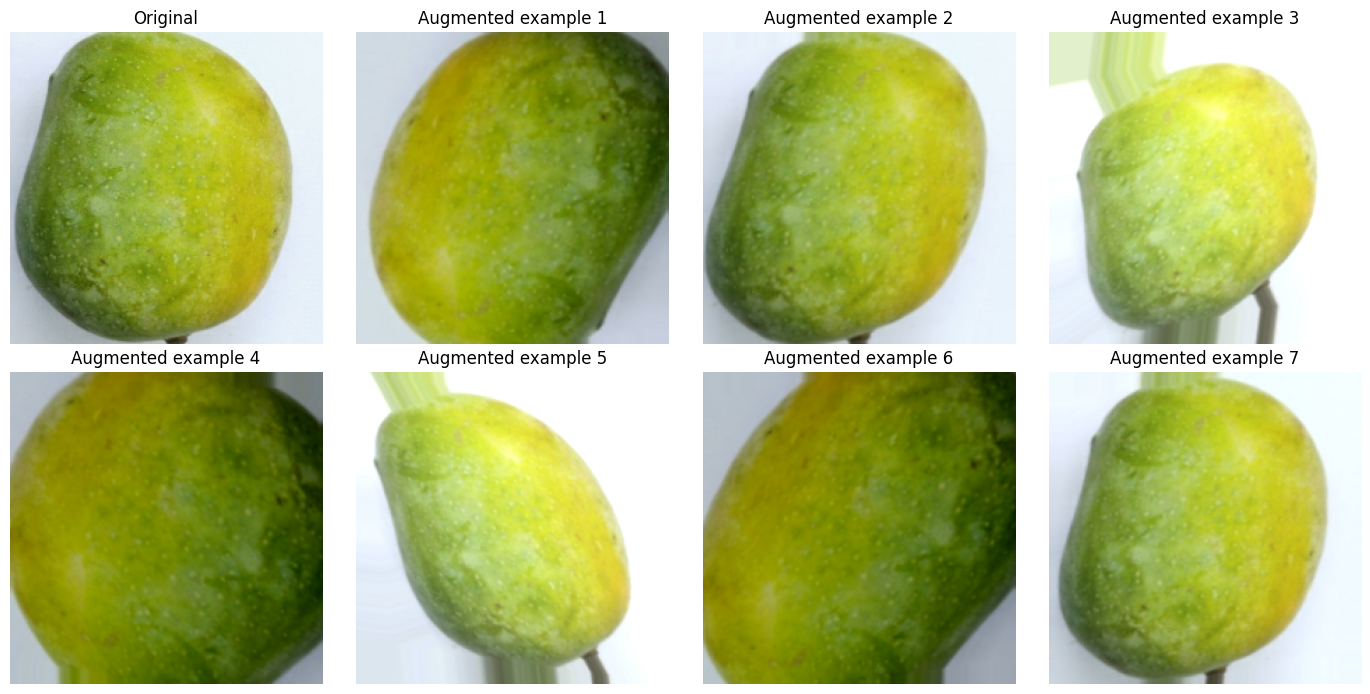

In [8]:
import matplotlib.pyplot as plt
sample_batch, _ = next(iter(train_raw))
one = sample_batch[:1]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    pixels = one[0].numpy() if i == 0 else augment(one, training=True)[0].numpy()
    ax.imshow(np.clip(pixels, 0, 255).astype('uint8'))
    ax.set_title('Original' if i == 0 else f'Augmented example {i}')
    ax.axis('off')
fig.tight_layout()
fig.savefig(RUN_DIR / 'augmentation_preview.png', dpi=150)
plt.show()
train_ds = train_raw.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)


## 4. Build the model and train both stages

**Purpose:** train one seven-class model using v3's architecture and 5 + 10 epoch schedule.
**Action:** run the next cells. Keep the tab connected and wait for both stages to finish.
**Expected result:** the best checkpoint from each stage is saved to this run's Drive folder.

Class weights give more importance to errors on smaller classes. They do not create new photos.
Stage 1 trains the new classifier. Stage 2 also adjusts the ImageNet feature extractor, while
BatchNormalization keeps its saved statistics. A stopped training run is not automatically resumed;
start a new run from Step 2 if training is incomplete.


In [9]:
from sklearn.utils.class_weight import compute_class_weight
train_labels = np.asarray([CLASS_NAMES.index(r['label']) for r in records if r['subset'] == 'train'])
weights = compute_class_weight('balanced', classes=np.arange(len(CLASS_NAMES)), y=train_labels)
class_weight = {i: float(w) for i, w in enumerate(weights)}
print('Class weights:', {CLASS_NAMES[i]: w for i, w in class_weight.items()})
base_model = tf.keras.applications.MobileNetV3Large(
    input_shape=IMAGE_SIZE + (3,),
    include_top=False,
    weights="imagenet")

base_model.trainable = False

inputs  = tf.keras.Input(shape=IMAGE_SIZE + (3,), name="input_image")
x       = base_model(inputs, training=False)
x       = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)
x       = tf.keras.layers.Dropout(0.2, name="dropout")(x)
logits  = tf.keras.layers.Dense(len(CLASS_NAMES), name="logits")(x)
outputs = tf.keras.layers.Activation("softmax", dtype="float32", name="probs")(logits)

model = tf.keras.Model(inputs, outputs, name="mangoleaf_v4")

print("Base layers      :", len(base_model.layers))
print("Trainable weights:", len(model.trainable_weights), "(stage 1: head only)")
model.summary()


Class weights: {'anthracnose': 0.7665402444163506, 'bacterial_black_spot': 1.2553485162180815, 'bacterial_canker': 0.7576009995835069, 'healthy_fruit': 3.3747680890538034, 'healthy_leaf': 0.7488678468505557, 'mango_scab': 1.6551410373066424, 'sooty_mold': 0.7445763405648792}
12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Base layers      : 187
Trainable weights: 2 (stage 1: head only)


Model: "mangoleaf_v4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 7, 7, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 7)              │         6,727 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Activation)              │ (None, 7)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,003,079 (11.46 MB)

 Trainable params: 6,727 (26.28 KB)

 Non-trainable params: 2,996,352 (11.43 MB)

Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.6399 - loss: 1.1098 - val_accuracy: 0.9130 - val_loss: 0.3230
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 28s 478ms/step - accuracy: 0.9109 - loss: 0.3566 - val_accuracy: 0.9412 - val_loss: 0.2164
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 40s 471ms/step - accuracy: 0.9335 - loss: 0.2504 - val_accuracy: 0.9437 - val_loss: 0.1749
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 444ms/step - accuracy: 0.9390 - loss: 0.2165 - val_accuracy: 0.9514 - val_loss: 0.1594
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 452ms/step - accuracy: 0.9500 - loss: 0.1904 - val_accuracy: 0.9540 - val_loss: 0.1438
Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 93s 971ms/step - accuracy: 0.9577 - loss: 0.1466 - val_accuracy: 0.9591 - val_loss: 0.1209
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 29s 495ms/step - accuracy: 0.9599 - loss: 0.1400 - val_accuracy: 0.9642 - val_loss: 0.1171
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 40s 470ms/step - accuracy: 0.9670 - loss: 0.1149 - val_accuracy: 0.

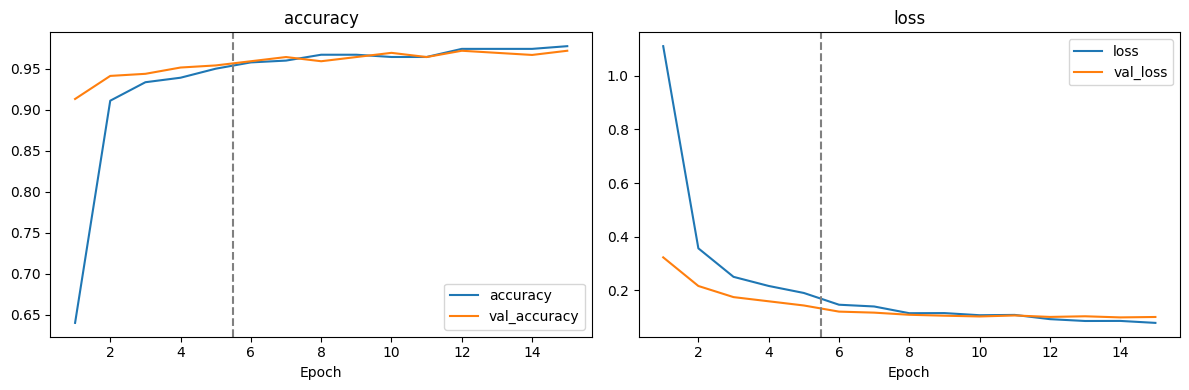

In [10]:
if sha256_file(RUN_DIR / 'plan.json') != PLAN_SHA256 or sha256_file(RUN_DIR / 'input_manifest.json') != MANIFEST_SHA256:
    raise RuntimeError('The saved plan or manifest changed. Start a new run.')
current = {'modelVersion': MODEL_VERSION, 'classes': CLASS_NAMES, 'seed': SEED, 'batchSize': BATCH_SIZE,
           'imageSize': list(IMAGE_SIZE), 'stage1': [STAGE1_EPOCHS, STAGE1_LR], 'stage2': [STAGE2_EPOCHS, STAGE2_LR],
           'augmentation': [AUG_FLIP, AUG_ROTATION_DEG, AUG_ZOOM, AUG_SHEAR, AUG_BRIGHTNESS],
           'preprocessing': PREPROCESSING, 'confidenceThreshold': CONFIDENCE_THRESHOLD,
           'minimumValidationRetention': MIN_ID_RETENTION, 'phashDistance': PHASH_DISTANCE}
if any(plan[k] != value for k, value in current.items()):
    raise RuntimeError('Settings changed after preparation. Start a new run from Step 2.')
verify_records_unchanged(records)
write_json_once(RUN_DIR / 'training_started.json', {'startedAt': datetime.now(timezone.utc).isoformat()})

class RequireFiniteMetrics(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if not all(math.isfinite(float(value)) for value in (logs or {}).values()):
            raise RuntimeError('Training produced non-finite values. Do not export this run.')

histories = []
for stage, epochs, learning_rate in [(1, STAGE1_EPOCHS, STAGE1_LR), (2, STAGE2_EPOCHS, STAGE2_LR)]:
    if stage == 2:
        base_model.trainable = True
        for layer in base_model.layers:
            if isinstance(layer, tf.keras.layers.BatchNormalization):
                layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    checkpoint = RUN_DIR / f'stage{stage}_best.weights.h5'
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                        class_weight=class_weight, callbacks=[RequireFiniteMetrics(),
                        tf.keras.callbacks.ModelCheckpoint(checkpoint, monitor='val_loss', mode='min',
                                                          save_best_only=True, save_weights_only=True)])
    model.load_weights(checkpoint)
    histories.append({k: [float(x) for x in values] for k, values in history.history.items()})
    write_json_once(RUN_DIR / f'stage{stage}_history.json', histories[-1])
write_json_once(RUN_DIR / 'training_history.json', histories)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['accuracy', 'loss']):
    for key in (metric, 'val_' + metric):
        values = histories[0][key] + histories[1][key]
        ax.plot(range(1, len(values) + 1), values, label=key)
    ax.axvline(STAGE1_EPOCHS + 0.5, color='grey', linestyle='--')
    ax.set_xlabel('Epoch'); ax.set_title(metric); ax.legend()
fig.tight_layout(); fig.savefig(RUN_DIR / 'training_history.png', dpi=150); plt.show()


## 5. Calibrate confidence and save the trained model

**Purpose:** adjust confidence using validation images without changing the predicted class.
**Action:** run this cell once after both training stages finish.
**Expected result:** `model_calibrated.keras` and `training_ready.json` are saved to Drive.

Temperature scaling adjusts the final layer's scores. The saved model includes that adjustment;
the application must not apply it again. This step does not choose rejection thresholds.


In [11]:
from scipy.optimize import minimize_scalar

logit_model = tf.keras.Model(model.inputs, model.get_layer("logits").output)

val_logits = logit_model.predict(val_ds, verbose=0)
val_labels = np.concatenate([y.numpy() for _, y in val_ds])

def nll(T):
    z = val_logits / T
    z = z - z.max(axis=1, keepdims=True)
    logp = z - np.log(np.exp(z).sum(axis=1, keepdims=True))
    return float(-logp[np.arange(len(val_labels)), val_labels].mean())

res = minimize_scalar(nll, bounds=(0.25, 20.0), method="bounded")
T = float(res.x)

print("Validation NLL before: {:.4f}".format(nll(1.0)))
print("Validation NLL after : {:.4f}".format(nll(T)))
print("Fitted temperature T = {:.4f}".format(T))
print("")
if T > 1.05:
    print("T above 1.0 means the model was OVERCONFIDENT. Confidence scores will drop.")
elif T < 0.95:
    print("T below 1.0 means the model was underconfident. Confidence scores will rise.")
else:
    print("T near 1.0 means the model was already reasonably calibrated.")

# Mean confidence before and after, for the record.
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

print("")
print("Mean top-1 confidence on validation:")
print("  before: {:.4f}".format(softmax(val_logits).max(axis=1).mean()))
print("  after : {:.4f}".format(softmax(val_logits / T).max(axis=1).mean()))
if not res.success or not math.isfinite(T) or T <= 0:
    raise RuntimeError('Temperature fitting failed.')
if (RUN_DIR / 'model_calibrated.keras').exists():
    raise RuntimeError('A calibrated model is already saved. Do not apply temperature twice.')
before = model.predict(val_ds, verbose=0)
kernel, bias = model.get_layer('logits').get_weights()
model.get_layer('logits').set_weights([kernel / T, bias / T])
after = model.predict(val_ds, verbose=0)
if not np.array_equal(before.argmax(axis=1), after.argmax(axis=1)):
    raise RuntimeError('Temperature folding changed a validation prediction.')
# Check the threshold notebook's image loader against the training loader.
np.testing.assert_allclose(after, predict_records(model, val_records), rtol=1e-4, atol=1e-5)
model.save(RUN_DIR / 'model_calibrated.keras')
reloaded = tf.keras.models.load_model(RUN_DIR / 'model_calibrated.keras', compile=False)
np.testing.assert_allclose(after, predict_records(reloaded, val_records), rtol=1e-4, atol=1e-5)
np.save(RUN_DIR / 'validation_probabilities.npy', after)
info = {**plan, 'temperature': T, 'temperatureFoldedIntoWeights': True,
        'validationCalibrationNll': {'before': nll(1.0), 'after': nll(T)},
        'classWeights': {CLASS_NAMES[i]: w for i, w in class_weight.items()},
        'baseLayerName': base_model.name, 'architecture': 'MobileNetV3Large + GAP + Dropout(0.2) + Dense(7) + Softmax',
        'modelSha256': sha256_file(RUN_DIR / 'model_calibrated.keras'),
        'inputManifestSha256': MANIFEST_SHA256, 'planSha256': PLAN_SHA256,
        'testPredictionsRun': False, 'status': 'experimental; thresholds not fitted'}
write_json_once(RUN_DIR / 'resume_info.json', info)
required = ['model_calibrated.keras', 'validation_probabilities.npy', 'resume_info.json',
            'input_manifest.json', 'plan.json', 'dataset_split.zip', 'duplicate_audit.json',
            'reviewed_images.json', 'raw_inventory.json', 'training_history.json']
write_json_once(RUN_DIR / 'training_ready.json', {
    'artifacts': {name: sha256_file(RUN_DIR / name) for name in required},
    'finishedAt': datetime.now(timezone.utc).isoformat(), 'testPredictionsRun': False})
print('TRAINING SAVED:', RUN_DIR)
print('The next step visualizes validation examples; it does not retrain.')


Validation NLL before: 0.0993
Validation NLL after : 0.0959
Fitted temperature T = 1.2508

T above 1.0 means the model was OVERCONFIDENT. Confidence scores will drop.

Mean top-1 confidence on validation:
  before: 0.9717
  after : 0.9638
TRAINING SAVED: /content/drive/MyDrive/mangoleaf_experiments/v4/training/v4-training-20260923T111044Z-4b60a5aa
The next step visualizes validation examples; it does not retrain.


## 6. Inspect validation Grad-CAM

**Purpose:** show which image regions influence one prediction per class.
**Action:** inspect leaf/fruit details and background regions in the heatmaps.
**Expected result:** `validation_grad_cam.png` and a ranked table of all seven class percentages for each pictured image. Tables use the calibrated scores before rejection gates. These scores describe one image; they are not per-class accuracy. Rounded percentages may total slightly above or below 100%. Heatmaps are diagnostic examples, not proof of accuracy.



Validation: val/anthracnose/anthracnose__20211008_124249 (Custom).jpg | actual: anthracnose | no rejection gates
Anthracnose               99.99%
Healthy Leaf               0.01%
Sooty Mold                 0.00%
Bacterial Canker           0.00%
Healthy Fruit              0.00%
Mango Scab                 0.00%
Bacterial Black Spot       0.00%

Validation: val/bacterial_black_spot/bacterial_black_spot__Bc104.jpg | actual: bacterial_black_spot | no rejection gates
Bacterial Black Spot      63.52%
Mango Scab                35.73%
Sooty Mold                 0.58%
Healthy Fruit              0.10%
Anthracnose                0.04%
Healthy Leaf               0.02%
Bacterial Canker           0.01%

Validation: val/bacterial_canker/bacterial_canker__IMG_20211106_120833 (Custom).jpg | actual: bacterial_canker | no rejection gates
Bacterial Canker          99.97%
Sooty Mold                 0.03%
Anthracnose                0.01%
Healthy Leaf               0.00%
Mango Scab                 0.00%
Heal

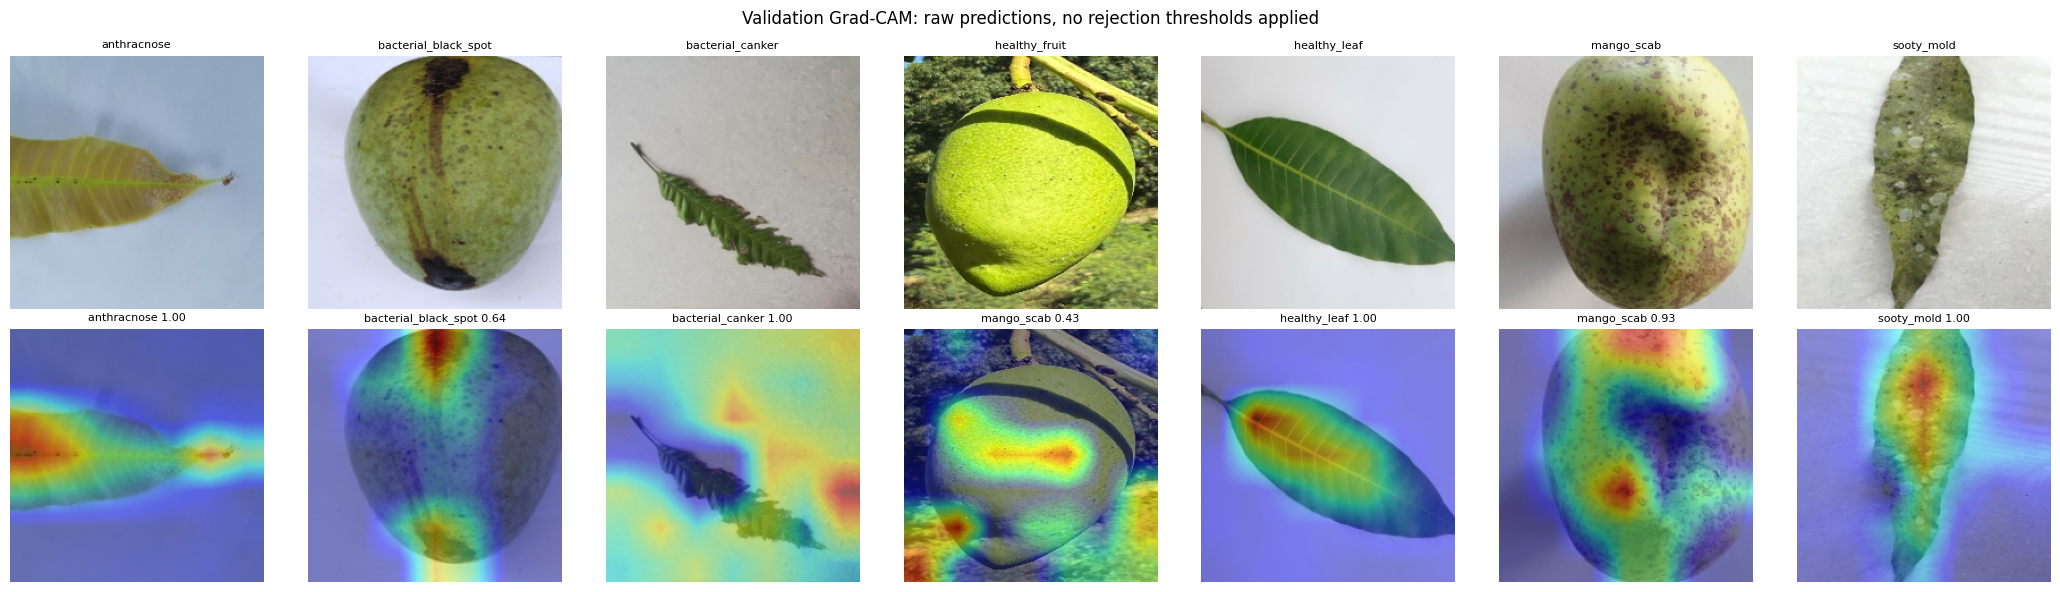

In [12]:
picked = [next(r for r in val_records if r['label'] == c) for c in CLASS_NAMES]
fig, axes = plt.subplots(2, len(CLASS_NAMES), figsize=(21, 6))
for column, row in enumerate(picked):
    pixels = load_pixels(row['path'])
    batch = pixels[None]
    with tf.GradientTape() as tape:
        features = base_model(batch, training=False)
        tape.watch(features)
        hidden = model.get_layer('gap')(features)
        hidden = model.get_layer('dropout')(hidden, training=False)
        logits = model.get_layer('logits')(hidden)
        index = tf.argmax(logits[0])
        score = logits[:, index]
    gradients = tape.gradient(score, features)
    if gradients is None:
        raise RuntimeError('Grad-CAM could not connect the feature map to the prediction.')
    heat = tf.nn.relu(tf.reduce_sum(features[0] * tf.reduce_mean(gradients, axis=(0, 1, 2)), axis=-1))
    heat = heat / (tf.reduce_max(heat) + 1e-9)
    heat = tf.image.resize(heat[..., None], IMAGE_SIZE).numpy()[..., 0]
    probabilities = model(batch, training=False).numpy()[0]
    confidence = float(probabilities[int(index)])
    print_class_probabilities(probabilities,
        f"Validation: {row['relativePath']} | actual: {row['label']} | no rejection gates")
    axes[0, column].imshow(pixels.numpy().astype('uint8'))
    axes[0, column].set_title(row['label'], fontsize=8)
    axes[1, column].imshow(pixels.numpy().astype('uint8'))
    axes[1, column].imshow(heat, cmap='jet', alpha=0.45, vmin=0, vmax=1)
    axes[1, column].set_title(f'{CLASS_NAMES[int(index)]} {confidence:.2f}', fontsize=8)
for ax in axes.flat:
    ax.axis('off')
fig.suptitle('Validation Grad-CAM: raw predictions, no rejection thresholds applied')
fig.tight_layout(); fig.savefig(RUN_DIR / 'validation_grad_cam.png', dpi=150); plt.show()


In [13]:
def verify_tfjs_export(folder):
    folder = Path(folder)
    graph = json.loads((folder / 'model.json').read_text(encoding='utf-8'))
    if graph.get('format') != 'graph-model':
        raise ValueError('Expected a TensorFlow.js Graph Model.')
    signature = graph.get('signature', {})
    outputs = list(signature.get('outputs', {}).values())
    inputs = list(signature.get('inputs', {}).values())
    dims = lambda tensor: [int(d['size']) for d in tensor['tensorShape']['dim']]
    if len(outputs) != 1 or dims(outputs[0])[-1:] != [len(CLASS_NAMES)]:
        raise ValueError('Export must expose seven output probabilities.')
    if len(inputs) != 1 or dims(inputs[0])[1:] != [224, 224, 3]:
        raise ValueError('Export input shape differs from the training plan.')
    dtypes = {'float32': '<f4', 'int32': '<i4', 'bool': '?'}
    used = set()
    for group in graph['weightsManifest']:
        parts = []
        for name in group['paths']:
            if name in used:
                raise ValueError('Repeated weight shard: ' + name)
            used.add(name)
            parts.append(inside(folder, name).read_bytes())
        buffer, offset = b''.join(parts), 0
        for weight in group['weights']:
            if 'quantization' in weight or weight['dtype'] not in dtypes:
                raise ValueError('This experiment requires unquantized float32 weights.')
            dtype = np.dtype(dtypes[weight['dtype']])
            count = math.prod(weight['shape'])
            size = count * dtype.itemsize
            if offset + size > len(buffer):
                raise ValueError('Truncated weight shard.')
            values = np.frombuffer(buffer[offset:offset + size], dtype=dtype)
            if not np.isfinite(values).all():
                raise ValueError('Non-finite values found in the exported weights.')
            offset += size
        if offset != len(buffer):
            raise ValueError('Weight manifest and shard sizes disagree.')
    if not used:
        raise ValueError('No exported weight shards.')
    return ['model.json'] + sorted(used)


## 7. Export the candidate for TensorFlow.js

**Purpose:** convert the saved calibrated model without retraining it.
**Action:** run the next cells. The converter setup keeps TensorFlow and NumPy unchanged.
**Expected result:** a seven-output Graph Model, float32 shards, and `training_complete.json`.

If Colab disconnects after `TRAINING SAVED`, rerun Step 1 and the helper-definition cells.
Set `RUN_DIR = Path('your saved Drive run folder')`, then resume here. Do not rerun training or calibration.
The threshold notebook can load a completed run without the original raw folder or a live training session.


In [14]:
ready = json.loads((RUN_DIR / 'training_ready.json').read_text(encoding='utf-8'))
verify_artifacts(RUN_DIR, ready['artifacts'])
info = json.loads((RUN_DIR / 'resume_info.json').read_text(encoding='utf-8'))
if info['classes'] != CLASS_NAMES or info['modelVersion'] != MODEL_VERSION:
    raise ValueError('The saved run is not the seven-class v4 experiment.')
if (RUN_DIR / 'training_complete.json').exists():
    raise RuntimeError('Export already completed. Open the threshold notebook with this run folder.')
model = tf.keras.models.load_model(RUN_DIR / 'model_calibrated.keras', compile=False)
# Failed exports get a new attempt folder; earlier files stay available for inspection.
EXPORT_DIR = RUN_DIR / ('v4-export-' + uuid.uuid4().hex[:8])
EXPORT_DIR.mkdir(exist_ok=False)
SAVED_MODEL = str(EXPORT_DIR / 'saved_model')
TFJS_DIR = str(EXPORT_DIR / 'model')
model.export(SAVED_MODEL, verbose=False)
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', '--no-deps', 'tensorflowjs==4.22.0'], check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '--quiet', '--no-deps', 'tensorflowjs==4.22.0'], returncode=0)

In [15]:
import re, os, sys, glob, json, subprocess
import importlib, importlib.util
import importlib.metadata as importlib_metadata

# Stubs live here, not in dist-packages, and are handed to the converter through
# PYTHONPATH. Real installed packages are left untouched.
STUB_DIR = str(EXPORT_DIR / "converter_stubs")

# Module name as imported -> name pip knows it by. None means no wheel exists for
# this Python version, so the module gets stubbed instead of installed.
PIP_NAME = {
    "tensorflow_decision_forests": None,
    "tensorflow_hub": "tensorflow-hub",
    "tf_keras": "tf-keras==" + ".".join(tf.__version__.split(".")[:2]) + ".0",
    "pkg_resources": "setuptools<81",
    "jax": "jax",
    "jaxlib": "jaxlib",
    "flax": "flax",
    "packaging": "packaging",
}

# Never stub these. If the failure is really inside TensorFlow itself, stubbing it
# would hide the problem rather than fix it.
NEVER_STUB = ("tensorflow", "numpy", "tensorflowjs")


def tfjs_dirs():
    # find_spec locates the package without running its __init__, so this works
    # even when importing tensorflowjs would raise.
    importlib.invalidate_caches()
    spec = importlib.util.find_spec("tensorflowjs")
    if spec is None or not spec.submodule_search_locations:
        return None
    return list(spec.submodule_search_locations)[0]


def version_of(dist):
    importlib.invalidate_caches()
    try:
        return importlib_metadata.version(dist)
    except Exception:
        return "not installed"


def patch_numpy_aliases(pkg_dir):
    # numpy 1.24 removed np.object, np.bool, np.int, np.float and np.str. Older
    # tensorflowjs builds reference them at import time. The \b boundary keeps the
    # rewrite off np.object_, np.bool_, np.float32 and friends. Re-run after every
    # pip install, in case pip moved to an older build.
    if not pkg_dir:
        return []
    names = ("object", "bool", "int", "float", "str", "complex")
    touched = []
    for path in glob.glob(os.path.join(pkg_dir, "**", "*.py"), recursive=True):
        try:
            with open(path, encoding="utf-8") as fh:
                src = fh.read()
        except (OSError, UnicodeDecodeError):
            continue
        new = src
        for n in names:
            new = re.sub(r"\bnp\.%s\b" % n, n, new)
            new = re.sub(r"\bnumpy\.%s\b" % n, n, new)
        if new != src:
            with open(path, "w", encoding="utf-8") as fh:
                fh.write(new)
            touched.append(os.path.relpath(path, pkg_dir))
    return touched


def write_stub(module_name):
    # Permissive placeholder. tensorflowjs imports these at load time but only uses
    # them for input formats this project never produces, so an empty shell is
    # enough to get past the import.
    d = os.path.join(STUB_DIR, module_name)
    os.makedirs(d, exist_ok=True)
    body = (
        "__version__ = '0.0.0-stub'\n"
        "\n"
        "class _Any(object):\n"
        "    def __getattr__(self, k):\n"
        "        return _Any\n"
        "    def __call__(self, *a, **k):\n"
        "        return _Any()\n"
        "\n"
        "def __getattr__(name):\n"
        "    return _Any\n"
    )
    for fname in ("__init__.py", "keras.py"):
        with open(os.path.join(d, fname), "w") as fh:
            fh.write(body)


def pip_install(pip_name, upgrade=True):
    # --no-deps is deliberate. A plain install can change the TensorFlow version,
    # which forces a runtime restart and loses the trained model held in memory.
    args = [sys.executable, "-m", "pip", "install", "-q", "--no-deps"]
    if upgrade:
        args.append("-U")
    args.append(pip_name)
    return subprocess.run(args, capture_output=True, text=True).returncode == 0


def run_converter():
    # List form, no shell. A shell would glob-expand the * in --quantize_float16=*.
    quant = ["--quantize_float16=*"] if QUANTIZE_FLOAT16 else []
    cmd = ([sys.executable, "-c", "from importlib.metadata import distribution; next(e for e in distribution('tensorflowjs').entry_points if e.name == 'tensorflowjs_converter').load()()", "--input_format=tf_saved_model"]
           + quant + [SAVED_MODEL, TFJS_DIR])
    env = dict(os.environ)
    env["TF_CPP_MIN_LOG_LEVEL"] = "2"
    if os.path.isdir(STUB_DIR):
        env["PYTHONPATH"] = STUB_DIR + os.pathsep + env.get("PYTHONPATH", "")
    print("     $", " ".join(cmd))
    return subprocess.run(cmd, capture_output=True, text=True, env=env)


def blame(text):
    """Which third-party package is failing to import inside the converter."""
    text = text or ""
    m = re.search(r"No module named '([^']+)'", text)
    if m:
        return m.group(1).split(".")[0]
    # Otherwise take the deepest traceback frame that sits in site-packages and
    # belongs to neither tensorflowjs nor tensorflow.
    found = None
    for path in re.findall(r'File "([^"]+)", line \d+, in <module>', text):
        parts = path.replace("\\", "/").split("/")
        for marker in ("dist-packages", "site-packages"):
            if marker in parts:
                top = parts[parts.index(marker) + 1]
                if top.endswith(".py"):
                    top = top[:-3]
                if top not in NEVER_STUB:
                    found = top
    return found


def tail(text, n=25):
    lines = [l for l in (text or "").strip().split("\n") if l.strip()]
    return "\n".join(lines[-n:])


os.makedirs(STUB_DIR, exist_ok=True)
pkg = tfjs_dirs()
print("numpy           :", np.__version__)
print("tensorflow      :", tf.__version__)
print("tensorflowjs    :", version_of("tensorflowjs"))
print("tensorflow_hub  :", version_of("tensorflow-hub"))
print("package dir     :", pkg)
print("")
if pkg is None:
    raise RuntimeError("tensorflowjs is not installed. Run cell #1, then this cell again.")

# --- Step A: tensorflow_hub 0.15 and older import tf.compat.v1.estimator, -----
# --- which TensorFlow removed in 2.16. Move to a release that does not. --------
print("Step A - upgrading tensorflow_hub (old builds need the removed Estimator API)")
pip_install("tensorflow-hub")
print("        tensorflow_hub :", version_of("tensorflow-hub"))
patch_numpy_aliases(tfjs_dirs())
proc = run_converter()

# --- Step B: repair loop. Upgrade the offending package once, then stub it. ----
tried = {}
for _ in range(8):
    if proc.returncode == 0:
        break
    mod = blame((proc.stderr or "") + "\n" + (proc.stdout or ""))
    if mod is None or mod in NEVER_STUB or mod not in PIP_NAME:
        break
    pip_name = PIP_NAME.get(mod, mod)
    stage = tried.get(mod, 0)
    print("")
    if stage == 0 and pip_name:
        print("Step B - {} is breaking the import, upgrading it".format(mod))
        if not pip_install(pip_name):
            print("        pip could not install {}".format(pip_name))
        else:
            print("        {} :".format(mod), version_of(pip_name))
        tried[mod] = 1
    elif stage <= 1 and mod in {"tensorflow_decision_forests", "tensorflow_hub", "jax", "jaxlib", "flax"}:
        print("Step B - {} still unusable, shadowing it with a stub".format(mod))
        print("        the SavedModel path does not use it")
        write_stub(mod)
        tried[mod] = 2
    else:
        break
    patch_numpy_aliases(tfjs_dirs())
    proc = run_converter()

# --- Report -------------------------------------------------------------------
model_json = os.path.join(TFJS_DIR, "model.json")
if proc.returncode != 0 or not os.path.isfile(model_json):
    print("")
    print("=" * 70)
    print("CONVERSION FAILED - exit code", proc.returncode)
    print("=" * 70)
    print(tail(proc.stderr) or tail(proc.stdout))
    print("")
    print("Nothing is lost. The trained, temperature-folded model is on disk at:")
    print("   ", SAVED_MODEL)
    print("Inspect the converter error. The saved calibrated model remains available; do not retrain.")
    raise RuntimeError("tensorflowjs_converter failed, see output above")

stubbed = sorted(d for d in os.listdir(STUB_DIR)
                 if os.path.isdir(os.path.join(STUB_DIR, d)))
print("")
print("Conversion succeeded with tensorflowjs", version_of("tensorflowjs"))
if stubbed:
    print("Stubbed for the converter only:", ", ".join(stubbed))
warn = tail(proc.stderr, 5)
if warn:
    print("")
    print("Converter notes (warnings here are normal):")
    print(warn)

# What the browser will load. These names must match src/lib/classifier.ts.
with open(model_json) as fh:
    mj = json.load(fh)
sig = mj.get("signature", {})
print("")
print("format       :", mj.get("format"), "| generated by tfjs", mj.get("generatedBy"))
print("inputs       :", list(sig.get("inputs", {}).keys()))
print("outputs      :", list(sig.get("outputs", {}).keys()))
print("weight shards:", len(mj.get("weightsManifest", [{}])[0].get("paths", [])))

print("")
total = 0
for f in sorted(os.listdir(TFJS_DIR)):
    p = os.path.join(TFJS_DIR, f)
    if not os.path.isfile(p):
        continue
    size = os.path.getsize(p)
    total += size
    print("  {:<28} {:>10,} bytes  ({:.2f} MB)".format(f, size, size / 1048576))
print("  {:<28} {:>10,} bytes  ({:.2f} MB)".format("TOTAL", total, total / 1048576))
print("")


numpy           : 2.1.3
tensorflow      : 2.20.0
tensorflowjs    : 4.22.0
tensorflow_hub  : 0.16.1
package dir     : /usr/local/lib/python3.13/dist-packages/tensorflowjs

Step A - upgrading tensorflow_hub (old builds need the removed Estimator API)
        tensorflow_hub : 0.16.1
     $ /usr/bin/python3 -c from importlib.metadata import distribution; next(e for e in distribution('tensorflowjs').entry_points if e.name == 'tensorflowjs_converter').load()() --input_format=tf_saved_model /content/drive/MyDrive/mangoleaf_experiments/v4/training/v4-training-20260923T111044Z-4b60a5aa/v4-export-f8905ea2/saved_model /content/drive/MyDrive/mangoleaf_experiments/v4/training/v4-training-20260923T111044Z-4b60a5aa/v4-export-f8905ea2/model

Step B - tensorflow_decision_forests still unusable, shadowing it with a stub
        the SavedModel path does not use it
     $ /usr/bin/python3 -c from importlib.metadata import distribution; next(e for e in distribution('tensorflowjs').entry_points if e.name ==

In [16]:
names = verify_tfjs_export(TFJS_DIR)
config = {'modelVersion': MODEL_VERSION, 'classes': CLASS_NAMES, 'inputSize': list(IMAGE_SIZE),
          'preprocessing': PREPROCESSING, 'temperature': info['temperature'],
          'temperatureFoldedIntoWeights': True, 'status': 'experimental; thresholds not fitted',
          'thresholds': {'confidenceThreshold': CONFIDENCE_THRESHOLD,
                         'marginThreshold': None, 'entropyThreshold': None}}
write_json_once(Path(TFJS_DIR) / 'model_config.json', config)
names.append('model_config.json')
verify_artifacts(RUN_DIR, ready['artifacts'])
artifacts = dict(ready['artifacts'])
for name in names:
    relative = (Path(TFJS_DIR) / name).relative_to(RUN_DIR).as_posix()
    artifacts[relative] = sha256_file(RUN_DIR / relative)
write_json_once(RUN_DIR / 'training_complete.json', {
    'modelVersion': MODEL_VERSION, 'classes': CLASS_NAMES, 'artifacts': artifacts,
    'tfjsDirectory': Path(TFJS_DIR).relative_to(RUN_DIR).as_posix(),
    'testPredictionsRun': False, 'finishedAt': datetime.now(timezone.utc).isoformat(),
    'status': 'experimental; evaluate before adoption'})
(RUN_DIR / 'requirements.txt').write_text(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
print('TRAINING AND EXPORT READY. Set TRAINING_RUN in the v4 threshold notebook to:')
print(RUN_DIR)
print('No test predictions or threshold fitting ran in this training notebook.')


TRAINING AND EXPORT READY. Set TRAINING_RUN in the v4 threshold notebook to:
/content/drive/MyDrive/mangoleaf_experiments/v4/training/v4-training-20260923T111044Z-4b60a5aa
No test predictions or threshold fitting ran in this training notebook.


## References and record keeping

- [Keras transfer learning](https://keras.io/guides/transfer_learning/): frozen-head training followed by low-rate fine-tuning.
- [Keras image loading](https://keras.io/api/data_loading/image/): RGB loading and bilinear resizing.
- [TensorFlow.js SavedModel conversion](https://www.tensorflow.org/js/tutorials/conversion/import_saved_model).
- [Data leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage): keep test data out of setting selection.

Download a separate completed-results notebook after running. Preserve this clean template and all historical v3 evidence.
This experiment does not change the application's six-class mapping, model assets, version labels, or diagnosis UI.
